# MediSense Spine — VinDr-SpineXR Optimized Kaggle Notebook

## Important update

The previous notebook was bottlenecked by **single-threaded DICOM preprocessing** (~1 image/sec).

This version uses a **parallel one-time DICOM cache**:

**DICOM → multiple DataLoader workers → 224×224 uint8 cache → fast training**

The cache is written atomically and marked complete only after all images are processed, so an interrupted run will not be mistaken for a valid cache.

### Dataset protocol

- Training: ~8,342 images
- Official test: ~2,077 images
- Validation: 10% of training studies
- Split is study-level to avoid leakage
- Test set remains untouched until final evaluation

### Experiments

1. DenseNet-201 baseline
2. DenseNet-201 + CBAM (MediSense)
3. Same validation/test protocol for both
4. Primary metric: AUROC
5. Secondary metrics: Accuracy, Precision, Sensitivity/Recall, Specificity, F1
6. Final comparison against the selected VinDr-SpineXR paper benchmark

### What to do

Run the notebook from the beginning after attaching the VinDr-SpineXR Kaggle dataset.

**Do not use the previous 1 img/s cache cell.**

The first cache build will take some time, but it should be substantially faster because DICOM decoding/resizing is parallelized. Once the cache is complete, rerunning the notebook reuses it.


# MediSense Spine — VinDr-SpineXR Kaggle Notebook

## Locked research plan

**Dataset:** Nhanhothanh Kaggle mirror of VinDr-SpineXR  
**Available:** 10,419 images (8,342 train + 2,077 test)  
**Official reference:** 10,466 images (8,389 train + 2,077 test)

The Kaggle mirror is missing 47 training images. We will **not** duplicate or fabricate them.

### Research task

VinDr-SpineXR does not provide the Fraiwan three-class labels. Therefore our primary task is the reference-aligned:

**Normal vs Abnormal**

- `0 = Normal` → `No finding`
- `1 = Abnormal` → one or more lesion findings

### Experiments

1. **DenseNet-201 baseline**
2. **MediSense = DenseNet-201 + CBAM**

The same study-level split, preprocessing, optimizer, validation procedure and final test set are used for both models.

### Main benchmark

The VinDr-SpineXR reference paper reported:

- DenseNet-201: **87.14% AUROC**
- Ensemble: **88.61% AUROC**

Our primary research goal is to beat the **88.61% AUROC** benchmark with the proposed MediSense model.

### Leakage rule

The supplied VinDr train/test split is preserved.

Inside the training studies, a **study-level validation split** is created. The official test set is not used for model selection.

### Final outputs

The notebook produces:

- AUROC
- Accuracy
- Precision
- Sensitivity / Recall
- Specificity
- F1-score
- Confusion matrix
- ROC curve
- Baseline vs MediSense comparison
- `.pth` checkpoints
- test prediction CSV


In [1]:
# 1. Configuration

import os
import random
import copy
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

IMG_SIZE = 224
BATCH_SIZE = 16

# Kaggle usually has multiple CPU cores.
# Increase to 8 only if your Kaggle session exposes enough CPU.
NUM_WORKERS = min(4, os.cpu_count() or 1)

EPOCHS = 15
LR = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 4

VAL_SIZE = 0.10

RUN_BASELINE = True
RUN_MEDISENSE = True

DEVICE = "cuda" if __import__("torch").cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("CPU workers:", NUM_WORKERS)


Device: cuda
CPU workers: 4


In [2]:
# 2. Imports and reproducibility

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision

import pydicom

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

warnings.filterwarnings("ignore")


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("pydicom:", pydicom.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
pydicom: 3.0.2
CUDA available: True
GPU: Tesla T4


In [3]:
# 3. Automatically locate the Kaggle VinDr-SpineXR dataset

INPUT_ROOT = Path("/kaggle/input")

train_csv_candidates = list(INPUT_ROOT.rglob("train.csv"))

if not train_csv_candidates:
    raise FileNotFoundError(
        "train.csv was not found. "
        "Attach the Nhanhothanh VinDr-SpineXR dataset to this Kaggle notebook."
    )

# Prefer the CSV inside an annotations folder.
annotation_candidates = [
    p for p in train_csv_candidates
    if p.parent.name.lower() == "annotations"
]

TRAIN_CSV = annotation_candidates[0] if annotation_candidates else train_csv_candidates[0]

DATA_ROOT = TRAIN_CSV.parent.parent

TEST_CSV = DATA_ROOT / "annotations" / "test.csv"
TRAIN_DIR = DATA_ROOT / "train_images"
TEST_DIR = DATA_ROOT / "test_images"

print("DATA ROOT :", DATA_ROOT)
print("TRAIN CSV :", TRAIN_CSV)
print("TEST CSV  :", TEST_CSV)
print("TRAIN DIR :", TRAIN_DIR)
print("TEST DIR  :", TEST_DIR)

assert TEST_CSV.exists(), f"Missing test.csv: {TEST_CSV}"
assert TRAIN_DIR.exists(), f"Missing train_images: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Missing test_images: {TEST_DIR}"

print("\nDataset folders found successfully.")


DATA ROOT : /kaggle/input/datasets/nhanhothanh/vindr-spinexr/vindr-spinexr/1.0.0
TRAIN CSV : /kaggle/input/datasets/nhanhothanh/vindr-spinexr/vindr-spinexr/1.0.0/annotations/train.csv
TEST CSV  : /kaggle/input/datasets/nhanhothanh/vindr-spinexr/vindr-spinexr/1.0.0/annotations/test.csv
TRAIN DIR : /kaggle/input/datasets/nhanhothanh/vindr-spinexr/vindr-spinexr/1.0.0/train_images
TEST DIR  : /kaggle/input/datasets/nhanhothanh/vindr-spinexr/vindr-spinexr/1.0.0/test_images

Dataset folders found successfully.


In [4]:
# 4. Load and inspect the annotations

train_ann = pd.read_csv(TRAIN_CSV)
test_ann = pd.read_csv(TEST_CSV)

print("Train annotation rows:", len(train_ann))
print("Test annotation rows :", len(test_ann))

print("\nColumns:")
print(train_ann.columns.tolist())

required_columns = {"image_id", "study_id", "lesion_type"}

missing_train = required_columns - set(train_ann.columns)
missing_test = required_columns - set(test_ann.columns)

assert not missing_train, f"Missing train columns: {missing_train}"
assert not missing_test, f"Missing test columns: {missing_test}"

print("\nTraining lesion types:")
display(
    train_ann["lesion_type"]
    .value_counts(dropna=False)
    .to_frame("annotation_rows")
)


Train annotation rows: 19442
Test annotation rows : 4748

Columns:
['study_id', 'series_id', 'image_id', 'rad_id', 'lesion_type', 'xmin', 'ymin', 'xmax', 'ymax']

Training lesion types:


,annotation_rows
lesion_type,
Osteophytes,12483
No finding,4233
Disc space narrowing,919
Other lesions,446
Surgical implant,428
Foraminal stenosis,387
Spondylolysthesis,279
Vertebral collapse,267


In [5]:
# 5. Build image-level Normal / Abnormal labels

# 0 = Normal ("No finding")
# 1 = Abnormal (one or more actual lesions)

def make_binary_labels(annotation_df):
    df = annotation_df.copy()
    df["image_id"] = df["image_id"].astype(str)

    grouped = (
        df.groupby("image_id")["lesion_type"]
        .apply(
            lambda values: int(
                any(
                    str(v).strip().lower() != "no finding"
                    for v in values
                )
            )
        )
        .reset_index(name="label")
    )

    return grouped


train_labels = make_binary_labels(train_ann)
test_labels = make_binary_labels(test_ann)

print("Images represented in train CSV:", len(train_labels))
print("Images represented in test CSV :", len(test_labels))

print("\nTRAIN CLASS COUNTS")
display(
    train_labels["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Normal", 1: "Abnormal"})
    .to_frame("images")
)

print("\nTEST CLASS COUNTS")
display(
    test_labels["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Normal", 1: "Abnormal"})
    .to_frame("images")
)


Images represented in train CSV: 8342
Images represented in test CSV : 2077

TRAIN CLASS COUNTS


,images
label,
Normal,4233
Abnormal,4109



TEST CLASS COUNTS


,images
label,
Normal,1070
Abnormal,1007


In [6]:
# 6. Find DICOM files robustly

def build_image_map(folder):
    folder = Path(folder)

    files = []
    for ext in ("*.dicom", "*.dcm", "*.DCM", "*.DICOM"):
        files.extend(folder.rglob(ext))

    # Key by filename stem.
    image_map = {}
    for p in files:
        image_map[p.stem] = p

    return image_map


train_file_map = build_image_map(TRAIN_DIR)
test_file_map = build_image_map(TEST_DIR)

print("Train image files detected:", len(train_file_map))
print("Test image files detected :", len(test_file_map))

if len(train_file_map) == 0 or len(test_file_map) == 0:
    raise RuntimeError(
        "No DICOM images were detected. "
        "Inspect the Kaggle dataset folder structure before training."
    )


Train image files detected: 8342
Test image files detected : 2077


In [7]:
# 7. Attach image paths and verify image/annotation coverage

def attach_paths(label_df, file_map):
    df = label_df.copy()
    df["path"] = df["image_id"].map(file_map)
    return df


train_df = attach_paths(train_labels, train_file_map)
test_df = attach_paths(test_labels, test_file_map)

missing_train_files = int(train_df["path"].isna().sum())
missing_test_files = int(test_df["path"].isna().sum())

print("Train labeled images without files:", missing_train_files)
print("Test labeled images without files :", missing_test_files)

# These should be zero for the available mirror.
assert missing_train_files == 0, (
    "Some training images in train.csv have no matching DICOM file."
)
assert missing_test_files == 0, (
    "Some test images in test.csv have no matching DICOM file."
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nUsable train images:", len(train_df))
print("Usable test images :", len(test_df))


Train labeled images without files: 0
Test labeled images without files : 0

Usable train images: 8342
Usable test images : 2077


In [8]:
# 8. Verify study-level train/test separation

train_studies = set(
    train_ann["study_id"].dropna().astype(str)
)

test_studies = set(
    test_ann["study_id"].dropna().astype(str)
)

study_overlap = train_studies & test_studies

print("Train studies:", len(train_studies))
print("Test studies :", len(test_studies))
print("Train/test study overlap:", len(study_overlap))

assert len(study_overlap) == 0, (
    "STOP: study leakage detected between train and test."
)

print("PASS: no train/test study leakage.")


Train studies: 3996
Test studies : 1000
Train/test study overlap: 0
PASS: no train/test study leakage.


In [9]:
# 9. Create a study-level validation split

# Attach study_id to each image.
image_to_study = (
    train_ann[["image_id", "study_id"]]
    .drop_duplicates("image_id")
    .copy()
)

image_to_study["image_id"] = image_to_study["image_id"].astype(str)
image_to_study["study_id"] = image_to_study["study_id"].astype(str)

train_df = train_df.merge(
    image_to_study,
    on="image_id",
    how="left"
)

assert train_df["study_id"].notna().all()

unique_studies = train_df["study_id"].unique()

study_train, study_val = train_test_split(
    unique_studies,
    test_size=VAL_SIZE,
    random_state=SEED,
    shuffle=True
)

study_train = set(study_train)
study_val = set(study_val)

train_split = train_df[
    train_df["study_id"].isin(study_train)
].copy()

val_split = train_df[
    train_df["study_id"].isin(study_val)
].copy()

train_val_overlap = (
    set(train_split["study_id"])
    & set(val_split["study_id"])
)

assert len(train_val_overlap) == 0

print("Training studies   :", len(study_train))
print("Validation studies :", len(study_val))
print("Training images    :", len(train_split))
print("Validation images  :", len(val_split))
print("Train/val study overlap:", len(train_val_overlap))


Training studies   : 3596
Validation studies : 400
Training images    : 7513
Validation images  : 829
Train/val study overlap: 0


In [10]:
# 10. Final dataset audit before training

def show_class_balance(df, title):
    counts = (
        df["label"]
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )

    table = pd.DataFrame({
        "Class": ["Normal", "Abnormal"],
        "Images": counts.values
    })

    table["Percentage"] = (
        100 * table["Images"] / len(df)
    )

    print(title)
    display(table)


show_class_balance(train_split, "TRAINING SET")
show_class_balance(val_split, "VALIDATION SET")
show_class_balance(test_df, "OFFICIAL TEST SET")

print("\nExpected Kaggle mirror:")
print("Training images: approximately 8342")
print("Testing images : approximately 2077")
print("Total           : approximately 10419")


TRAINING SET


,Class,Images,Percentage
0,Normal,3833,51.018235
1,Abnormal,3680,48.981765


VALIDATION SET


,Class,Images,Percentage
0,Normal,400,48.250905
1,Abnormal,429,51.749095


OFFICIAL TEST SET


,Class,Images,Percentage
0,Normal,1070,51.51661
1,Abnormal,1007,48.48339



Expected Kaggle mirror:
Training images: approximately 8342
Testing images : approximately 2077
Total           : approximately 10419


Sample file: 00073745e02e69432c002b527c565151.dicom
Original shape: (2820, 1143)
dtype: uint8
Min/Max: 0 255


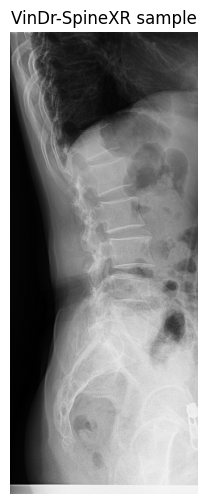

In [11]:
# 11. Fast DICOM preprocessing utilities

def dicom_to_uint8(path):
    ds = pydicom.dcmread(
        str(path),
        force=True
    )

    image = ds.pixel_array.astype(
        np.float32
    )

    slope = float(
        getattr(ds, "RescaleSlope", 1.0)
    )
    intercept = float(
        getattr(ds, "RescaleIntercept", 0.0)
    )

    image = image * slope + intercept

    if getattr(
        ds,
        "PhotometricInterpretation",
        ""
    ) == "MONOCHROME1":
        image = image.max() - image

    image -= image.min()

    max_value = image.max()

    if max_value > 0:
        image /= max_value

    return (
        image * 255.0
    ).clip(
        0, 255
    ).astype(
        np.uint8
    )


def resize_uint8(image):
    tensor = torch.from_numpy(
        image
    ).float()[None, None]

    tensor = F.interpolate(
        tensor,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )

    return (
        tensor[0, 0]
        .clamp(0, 255)
        .byte()
        .numpy()
    )


sample_path = train_split.iloc[0]["path"]
sample_image = dicom_to_uint8(sample_path)

print("Sample file:", sample_path.name)
print("Original shape:", sample_image.shape)
print("dtype:", sample_image.dtype)
print("Min/Max:", sample_image.min(), sample_image.max())

plt.figure(figsize=(6, 6))
plt.imshow(sample_image, cmap="gray")
plt.axis("off")
plt.title("VinDr-SpineXR sample")
plt.show()


In [12]:
# 12. Image transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.ToPILImage(),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=5
    ),

    transforms.ToTensor(),

    transforms.Lambda(
        lambda x: x.repeat(3, 1, 1)
    ),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    ),
])

eval_transform = transforms.Compose([
    transforms.ToPILImage(),

    transforms.ToTensor(),

    transforms.Lambda(
        lambda x: x.repeat(3, 1, 1)
    ),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    ),
])


In [13]:
# 13. PARALLEL IMAGE CACHE + FAST TRAINING DATALOADERS
#
# The old notebook created the cache in a single Python loop
# (~1 image/sec). This version uses DataLoader workers to decode
# and resize DICOM files in parallel.
#
# A completed cache is marked with .complete. Interrupted runs
# are never reused.

CACHE_ROOT = Path("/kaggle/working/medisense_spine_cache")
CACHE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


class PreprocessDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(
            drop=True
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = dicom_to_uint8(
            row["path"]
        )

        image = resize_uint8(
            image
        )

        return (
            torch.from_numpy(image),
            str(row["image_id"]),
            int(row["label"])
        )


def build_parallel_cache(
    dataframe,
    cache_name,
    workers=NUM_WORKERS
):

    dataframe = dataframe.reset_index(
        drop=True
    )

    final_npy = (
        CACHE_ROOT /
        f"{cache_name}.npy"
    )

    final_meta = (
        CACHE_ROOT /
        f"{cache_name}_meta.csv"
    )

    complete_marker = (
        CACHE_ROOT /
        f"{cache_name}.complete"
    )

    if (
        final_npy.exists()
        and final_meta.exists()
        and complete_marker.exists()
    ):

        meta = pd.read_csv(
            final_meta
        )

        if len(meta) == len(dataframe):

            print(
                "Using completed cache:",
                final_npy
            )

            return (
                np.load(
                    final_npy,
                    mmap_mode="r"
                ),
                meta
            )

    # Temporary files prevent interrupted runs from
    # being mistaken for complete caches.
    temp_npy = (
        CACHE_ROOT /
        f"{cache_name}.tmp.npy"
    )

    temp_meta = (
        CACHE_ROOT /
        f"{cache_name}_tmp_meta.csv"
    )

    for p in [
        temp_npy,
        temp_meta,
        complete_marker
    ]:
        if p.exists():
            p.unlink()

    print()
    print("=" * 65)
    print(
        f"BUILDING PARALLEL CACHE: {cache_name}"
    )
    print("=" * 65)
    print(
        "Images:",
        len(dataframe)
    )
    print(
        "Workers:",
        workers
    )

    dataset = PreprocessDataset(
        dataframe
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=workers,
        pin_memory=False,
        persistent_workers=(workers > 0),
        prefetch_factor=2 if workers > 0 else None
    )

    # Create a memmap file with a temporary name.
    array = np.lib.format.open_memmap(
        temp_npy,
        mode="w+",
        dtype=np.uint8,
        shape=(
            len(dataframe),
            IMG_SIZE,
            IMG_SIZE
        )
    )

    meta_rows = []

    completed = 0
    start_time = time.time()

    for images, ids, labels in loader:

        batch_n = images.shape[0]

        array[
            completed:
            completed + batch_n
        ] = images.numpy()

        for image_id, label in zip(
            ids,
            labels.numpy()
        ):
            meta_rows.append({
                "image_id": str(image_id),
                "label": int(label)
            })

        completed += batch_n

        if (
            completed % 512 == 0
            or completed == len(dataframe)
        ):

            elapsed = (
                time.time()
                - start_time
            )

            rate = (
                completed
                / max(elapsed, 1e-6)
            )

            eta = (
                len(dataframe) - completed
            ) / max(rate, 1e-6)

            print(
                f"Cached {completed}/"
                f"{len(dataframe)} | "
                f"{rate:.1f} img/s | "
                f"ETA {eta/60:.1f} min"
            )

    array.flush()

    meta = pd.DataFrame(
        meta_rows
    )

    meta.to_csv(
        temp_meta,
        index=False
    )

    # Only publish the cache after it is complete.
    temp_npy.replace(
        final_npy
    )

    temp_meta.replace(
        final_meta
    )

    complete_marker.touch()

    print()
    print(
        "CACHE COMPLETE:",
        final_npy
    )

    return (
        np.load(
            final_npy,
            mmap_mode="r"
        ),
        meta
    )


# Build the complete training and official-test caches.
train_cache, train_meta = build_parallel_cache(
    train_df,
    "train_8342"
)

test_cache, test_meta = build_parallel_cache(
    test_df,
    "test_2077"
)


# ------------------------------------------------------------
# Map image IDs to cache indexes.
# ------------------------------------------------------------

train_index = {
    image_id: i
    for i, image_id in enumerate(
        train_meta["image_id"].astype(str)
    )
}

test_index = {
    image_id: i
    for i, image_id in enumerate(
        test_meta["image_id"].astype(str)
    )
}


train_split = train_split.copy()
val_split = val_split.copy()
test_df = test_df.copy()


train_split["cache_idx"] = (
    train_split["image_id"]
    .astype(str)
    .map(train_index)
)

val_split["cache_idx"] = (
    val_split["image_id"]
    .astype(str)
    .map(train_index)
)

test_df["cache_idx"] = (
    test_df["image_id"]
    .astype(str)
    .map(test_index)
)


assert train_split["cache_idx"].notna().all()
assert val_split["cache_idx"].notna().all()
assert test_df["cache_idx"].notna().all()


train_split["cache_idx"] = (
    train_split["cache_idx"].astype(int)
)

val_split["cache_idx"] = (
    val_split["cache_idx"].astype(int)
)

test_df["cache_idx"] = (
    test_df["cache_idx"].astype(int)
)


# ------------------------------------------------------------
# Cached dataset
# ------------------------------------------------------------

class CachedVinDrDataset(Dataset):

    def __init__(
        self,
        dataframe,
        cache,
        transform
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.cache = cache
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = np.asarray(
            self.cache[
                int(row["cache_idx"])
            ]
        )

        if self.transform is not None:
            image = self.transform(
                image
            )

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return (
            image,
            label,
            str(row["image_id"])
        )


# ------------------------------------------------------------
# Training / validation / test datasets
# ------------------------------------------------------------

train_ds = CachedVinDrDataset(
    train_split,
    train_cache,
    train_transform
)

val_ds = CachedVinDrDataset(
    val_split,
    train_cache,
    eval_transform
)

test_ds = CachedVinDrDataset(
    test_df,
    test_cache,
    eval_transform
)


# Cached images are fast, so 2 workers is enough.
# This avoids unnecessary CPU overhead during training.
TRAIN_WORKERS = min(
    2,
    os.cpu_count() or 1
)

loader_kwargs = {
    "num_workers": TRAIN_WORKERS,
    "pin_memory": (
        DEVICE == "cuda"
    )
}

if TRAIN_WORKERS > 0:
    loader_kwargs[
        "persistent_workers"
    ] = True
    loader_kwargs[
        "prefetch_factor"
    ] = 2


train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **loader_kwargs
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs
)


# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------

start = time.time()

batch_images, batch_labels, batch_ids = next(
    iter(train_loader)
)

elapsed = time.time() - start

print()
print("=" * 65)
print("FAST DATALOADER SANITY CHECK")
print("=" * 65)

print(
    "Train images      :",
    len(train_ds)
)

print(
    "Validation images :",
    len(val_ds)
)

print(
    "Official test     :",
    len(test_ds)
)

print(
    "Batch shape       :",
    tuple(batch_images.shape)
)

print(
    "Labels shape      :",
    tuple(batch_labels.shape)
)

print(
    "First batch time  :",
    round(elapsed, 2),
    "sec"
)

assert batch_images.shape[1:] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)

assert batch_labels.ndim == 1

print()
print("PASS: CachedVinDrDataset is defined.")
print("PASS: Fast DataLoader is working.")



BUILDING PARALLEL CACHE: train_8342
Images: 8342
Workers: 4
Cached 512/8342 | 2.7 img/s | ETA 48.5 min
Cached 1024/8342 | 2.7 img/s | ETA 44.9 min
Cached 1536/8342 | 2.7 img/s | ETA 42.5 min
Cached 2048/8342 | 2.7 img/s | ETA 38.9 min
Cached 2560/8342 | 2.7 img/s | ETA 36.1 min
Cached 3072/8342 | 2.7 img/s | ETA 32.5 min
Cached 3584/8342 | 2.7 img/s | ETA 29.0 min
Cached 4096/8342 | 2.8 img/s | ETA 25.3 min
Cached 4608/8342 | 2.8 img/s | ETA 22.4 min
Cached 5120/8342 | 2.8 img/s | ETA 19.1 min
Cached 5632/8342 | 2.8 img/s | ETA 16.1 min
Cached 6144/8342 | 2.8 img/s | ETA 13.1 min
Cached 6656/8342 | 2.8 img/s | ETA 10.0 min
Cached 7168/8342 | 2.8 img/s | ETA 7.0 min
Cached 7680/8342 | 2.8 img/s | ETA 3.9 min
Cached 8192/8342 | 2.8 img/s | ETA 0.9 min
Cached 8342/8342 | 2.8 img/s | ETA 0.0 min

CACHE COMPLETE: /kaggle/working/medisense_spine_cache/train_8342.npy

BUILDING PARALLEL CACHE: test_2077
Images: 2077
Workers: 4
Cached 512/2077 | 2.6 img/s | ETA 10.0 min
Cached 1024/2077 | 2.7 

In [14]:
# 14. Calculate class weighting from TRAINING DATA ONLY

train_counts = (
    train_split["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

negative_count = int(train_counts[0])
positive_count = int(train_counts[1])

pos_weight_value = (
    negative_count / positive_count
    if positive_count > 0
    else 1.0
)

POS_WEIGHT = torch.tensor(
    pos_weight_value,
    dtype=torch.float32,
    device=DEVICE
)

print("Normal training images :", negative_count)
print("Abnormal training images:", positive_count)
print("Positive-class loss weight:", pos_weight_value)


Normal training images : 3833
Abnormal training images: 3680
Positive-class loss weight: 1.0415760869565218


## 15. Model definitions

### Baseline
ImageNet-pretrained **DenseNet-201** with a binary classifier.

### MediSense
The same DenseNet-201 feature extractor followed by **CBAM**:

`Channel Attention → Spatial Attention → Global Pooling → Classifier`

This is an ablation-style comparison: the data, split, preprocessing and training procedure remain the same while the proposed attention module is introduced.


In [15]:
# 16. DenseNet-201 baseline

def load_densenet201():

    try:
        weights = models.DenseNet201_Weights.DEFAULT
        model = models.densenet201(weights=weights)
        print("Loaded ImageNet-pretrained DenseNet-201.")
    except Exception as e:
        print("WARNING: pretrained weights could not be loaded.")
        print("Reason:", e)
        print("Using randomly initialized DenseNet-201.")
        model = models.densenet201(weights=None)

    return model


def make_densenet201_baseline():

    model = load_densenet201()

    in_features = model.classifier.in_features

    model.classifier = nn.Sequential(
        nn.Dropout(0.30),
        nn.Linear(in_features, 1)
    )

    return model


print("DenseNet-201 baseline factory ready.")


DenseNet-201 baseline factory ready.


In [16]:
# 17. CBAM implementation

class ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 8)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(
                channels,
                hidden,
                kernel_size=1,
                bias=False
            ),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                hidden,
                channels,
                kernel_size=1,
                bias=False
            )
        )

    def forward(self, x):

        avg = self.mlp(
            self.avg_pool(x)
        )

        mx = self.mlp(
            self.max_pool(x)
        )

        attention = torch.sigmoid(
            avg + mx
        )

        return x * attention


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

    def forward(self, x):

        avg = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        mx, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        attention = torch.sigmoid(
            self.conv(
                torch.cat(
                    [avg, mx],
                    dim=1
                )
            )
        )

        return x * attention


class CBAM(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16
    ):
        super().__init__()

        self.channel = ChannelAttention(
            channels,
            reduction
        )

        self.spatial = SpatialAttention()

    def forward(self, x):

        x = self.channel(x)
        x = self.spatial(x)

        return x


In [17]:
# 18. MediSense DenseNet-201 + CBAM

class MediSenseDenseNet201(nn.Module):

    def __init__(self):

        super().__init__()

        backbone = load_densenet201()

        channels = backbone.classifier.in_features

        self.features = backbone.features

        self.cbam = CBAM(
            channels=channels,
            reduction=16
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.30),
            nn.Linear(channels, 1)
        )

    def forward(self, x):

        x = self.features(x)
        x = F.relu(x, inplace=True)

        x = self.cbam(x)

        x = self.pool(x)
        x = torch.flatten(x, 1)

        x = self.classifier(x)

        return x.squeeze(1)


print("MediSense DenseNet-201 + CBAM factory ready.")


MediSense DenseNet-201 + CBAM factory ready.


In [18]:
# 19. Prediction and metric utilities

@torch.no_grad()
def predict(model, loader):

    model.eval()

    all_labels = []
    all_probs = []
    all_ids = []

    for images, labels, ids in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(images)

        probs = torch.sigmoid(logits)

        all_labels.extend(
            labels.cpu().numpy().astype(int)
        )

        all_probs.extend(
            probs.cpu().numpy()
        )

        all_ids.extend(ids)

    return (
        np.asarray(all_labels),
        np.asarray(all_probs),
        all_ids
    )


def select_youden_threshold(y_true, probs):

    fpr, tpr, thresholds = roc_curve(
        y_true,
        probs
    )

    j = tpr - fpr

    idx = np.argmax(j)

    threshold = thresholds[idx]

    if not np.isfinite(threshold):
        threshold = 0.5

    return float(threshold)


def calculate_metrics(
    y_true,
    probs,
    threshold=0.5
):

    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)

    predictions = (
        probs >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    metrics = {
        "AUROC": roc_auc_score(
            y_true,
            probs
        ),
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Sensitivity": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        )
    }

    return metrics, predictions


In [19]:
# 20. Training function — corrected BCE shape + AMP

def train_model(
    model,
    model_name
):

    model = model.to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=POS_WEIGHT
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1,
        min_lr=1e-6
    )

    use_amp = (
        DEVICE == "cuda"
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_amp
    )

    best_state = copy.deepcopy(
        model.state_dict()
    )

    best_val_auroc = -np.inf

    epochs_without_improvement = 0

    history = []

    for epoch in range(
        1,
        EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        total_examples = 0

        start_time = time.time()

        for images, labels, _ in train_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):

                logits = model(
                    images
                )

                # IMPORTANT:
                # DenseNet classifier returns [B, 1]
                # while labels are [B].
                logits = logits.reshape(-1)
                labels = labels.reshape(-1)

                loss = criterion(
                    logits,
                    labels
                )

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            n = images.size(0)

            running_loss += (
                loss.item() * n
            )

            total_examples += n

        train_loss = (
            running_loss /
            max(total_examples, 1)
        )

        # Validation only.
        # Official test remains untouched.
        y_val, p_val, _ = predict(
            model,
            val_loader
        )

        val_auroc = roc_auc_score(
            y_val,
            p_val
        )

        scheduler.step(
            val_auroc
        )

        elapsed = (
            time.time()
            - start_time
        )

        current_lr = (
            optimizer.param_groups[0]["lr"]
        )

        print(
            f"{model_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"loss={train_loss:.4f} | "
            f"val_AUROC={val_auroc:.4f} | "
            f"lr={current_lr:.2e} | "
            f"time={elapsed/60:.1f} min"
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_AUROC": val_auroc,
            "lr": current_lr
        })

        if val_auroc > best_val_auroc:

            best_val_auroc = val_auroc

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping triggered."
            )

            break

    model.load_state_dict(
        best_state
    )

    print(
        f"Best validation AUROC: "
        f"{best_val_auroc:.4f}"
    )

    return (
        model,
        pd.DataFrame(history)
    )


In [20]:
# 21. Train DenseNet-201 baseline

baseline_history = None
baseline_threshold = 0.5
baseline_metrics = None

if RUN_BASELINE:

    seed_everything(SEED)

    baseline_model = (
        make_densenet201_baseline()
        .to(DEVICE)
    )

    baseline_model, baseline_history = train_model(
        baseline_model,
        "DenseNet-201"
    )

    # Select threshold from validation only.
    y_val_b, p_val_b, _ = predict(
        baseline_model,
        val_loader
    )

    baseline_threshold = (
        select_youden_threshold(
            y_val_b,
            p_val_b
        )
    )

    print(
        "\nBaseline validation threshold:",
        baseline_threshold
    )

    checkpoint = {
        "model_name": "DenseNet-201 baseline",
        "state_dict": baseline_model.state_dict(),
        "img_size": IMG_SIZE,
        "seed": SEED,
        "threshold": baseline_threshold
    }

    baseline_path = (
        "/kaggle/working/"
        "medisense_spine_densenet201_baseline.pth"
    )

    torch.save(
        checkpoint,
        baseline_path
    )

    print("Saved:", baseline_path)


Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 190MB/s] 


Loaded ImageNet-pretrained DenseNet-201.
DenseNet-201 | Epoch 01/15 | loss=0.5576 | val_AUROC=0.8387 | lr=1.00e-04 | time=1.3 min
DenseNet-201 | Epoch 02/15 | loss=0.4920 | val_AUROC=0.8632 | lr=1.00e-04 | time=1.2 min
DenseNet-201 | Epoch 03/15 | loss=0.4544 | val_AUROC=0.8796 | lr=1.00e-04 | time=1.2 min
DenseNet-201 | Epoch 04/15 | loss=0.4153 | val_AUROC=0.8704 | lr=1.00e-04 | time=1.2 min
DenseNet-201 | Epoch 05/15 | loss=0.3752 | val_AUROC=0.8676 | lr=5.00e-05 | time=1.2 min
DenseNet-201 | Epoch 06/15 | loss=0.3012 | val_AUROC=0.8860 | lr=5.00e-05 | time=1.2 min
DenseNet-201 | Epoch 07/15 | loss=0.2405 | val_AUROC=0.8718 | lr=5.00e-05 | time=1.2 min
DenseNet-201 | Epoch 08/15 | loss=0.1881 | val_AUROC=0.8694 | lr=2.50e-05 | time=1.2 min
DenseNet-201 | Epoch 09/15 | loss=0.1216 | val_AUROC=0.8678 | lr=2.50e-05 | time=1.3 min
DenseNet-201 | Epoch 10/15 | loss=0.0886 | val_AUROC=0.8784 | lr=1.25e-05 | time=1.2 min
Early stopping triggered.
Best validation AUROC: 0.8860

Baseline val

In [21]:
# 22. Final baseline test evaluation

if RUN_BASELINE:

    # Official test is used ONLY here.
    y_test_b, p_test_b, test_ids_b = predict(
        baseline_model,
        test_loader
    )

    baseline_metrics, baseline_pred = (
        calculate_metrics(
            y_test_b,
            p_test_b,
            threshold=baseline_threshold
        )
    )

    print("=" * 65)
    print("DENSENET-201 BASELINE — FINAL TEST")
    print("=" * 65)

    for name, value in baseline_metrics.items():
        print(f"{name:20s}: {value:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_test_b,
            baseline_pred,
            target_names=[
                "Normal",
                "Abnormal"
            ],
            digits=4
        )
    )

    print("Confusion matrix:")
    print(
        confusion_matrix(
            y_test_b,
            baseline_pred,
            labels=[0, 1]
        )
    )


DENSENET-201 BASELINE — FINAL TEST
AUROC               : 0.8812
Accuracy            : 0.8012
Precision           : 0.8337
Sensitivity         : 0.7368
Specificity         : 0.8617
F1                  : 0.7823

Classification report:
              precision    recall  f1-score   support

      Normal     0.7767    0.8617    0.8170      1070
    Abnormal     0.8337    0.7368    0.7823      1007

    accuracy                         0.8012      2077
   macro avg     0.8052    0.7993    0.7997      2077
weighted avg     0.8044    0.8012    0.8002      2077

Confusion matrix:
[[922 148]
 [265 742]]


In [22]:
# 23. Train MediSense + CBAM

medisense_history = None
medisense_threshold = 0.5
medisense_metrics = None

if RUN_MEDISENSE:

    seed_everything(SEED)

    medisense_model = (
        MediSenseDenseNet201()
        .to(DEVICE)
    )

    medisense_model, medisense_history = train_model(
        medisense_model,
        "MediSense + CBAM"
    )

    # Select threshold from validation only.
    y_val_m, p_val_m, _ = predict(
        medisense_model,
        val_loader
    )

    medisense_threshold = (
        select_youden_threshold(
            y_val_m,
            p_val_m
        )
    )

    print(
        "\nMediSense validation threshold:",
        medisense_threshold
    )

    checkpoint = {
        "model_name": "MediSense DenseNet-201 + CBAM",
        "state_dict": medisense_model.state_dict(),
        "img_size": IMG_SIZE,
        "seed": SEED,
        "threshold": medisense_threshold
    }

    medisense_path = (
        "/kaggle/working/"
        "medisense_spine_densenet201_cbam.pth"
    )

    torch.save(
        checkpoint,
        medisense_path
    )

    print("Saved:", medisense_path)


Loaded ImageNet-pretrained DenseNet-201.
MediSense + CBAM | Epoch 01/15 | loss=0.5436 | val_AUROC=0.8335 | lr=1.00e-04 | time=1.3 min
MediSense + CBAM | Epoch 02/15 | loss=0.4693 | val_AUROC=0.8558 | lr=1.00e-04 | time=1.3 min
MediSense + CBAM | Epoch 03/15 | loss=0.4322 | val_AUROC=0.8594 | lr=1.00e-04 | time=1.3 min
MediSense + CBAM | Epoch 04/15 | loss=0.3990 | val_AUROC=0.8721 | lr=1.00e-04 | time=1.3 min
MediSense + CBAM | Epoch 05/15 | loss=0.3741 | val_AUROC=0.8756 | lr=1.00e-04 | time=1.3 min
MediSense + CBAM | Epoch 06/15 | loss=0.3360 | val_AUROC=0.8517 | lr=1.00e-04 | time=1.3 min
MediSense + CBAM | Epoch 07/15 | loss=0.3001 | val_AUROC=0.8746 | lr=5.00e-05 | time=1.3 min
MediSense + CBAM | Epoch 08/15 | loss=0.2032 | val_AUROC=0.8778 | lr=5.00e-05 | time=1.3 min
MediSense + CBAM | Epoch 09/15 | loss=0.1498 | val_AUROC=0.8826 | lr=5.00e-05 | time=1.3 min
MediSense + CBAM | Epoch 10/15 | loss=0.1274 | val_AUROC=0.8766 | lr=5.00e-05 | time=1.3 min
MediSense + CBAM | Epoch 11/1

In [23]:
# 24. Final MediSense test evaluation

if RUN_MEDISENSE:

    y_test_m, p_test_m, test_ids_m = predict(
        medisense_model,
        test_loader
    )

    medisense_metrics, medisense_pred = (
        calculate_metrics(
            y_test_m,
            p_test_m,
            threshold=medisense_threshold
        )
    )

    print("=" * 65)
    print("MEDISENSE + CBAM — FINAL TEST")
    print("=" * 65)

    for name, value in medisense_metrics.items():
        print(f"{name:20s}: {value:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_test_m,
            medisense_pred,
            target_names=[
                "Normal",
                "Abnormal"
            ],
            digits=4
        )
    )

    print("Confusion matrix:")
    print(
        confusion_matrix(
            y_test_m,
            medisense_pred,
            labels=[0, 1]
        )
    )


MEDISENSE + CBAM — FINAL TEST
AUROC               : 0.8769
Accuracy            : 0.8016
Precision           : 0.8295
Sensitivity         : 0.7438
Specificity         : 0.8561
F1                  : 0.7843

Classification report:
              precision    recall  f1-score   support

      Normal     0.7802    0.8561    0.8164      1070
    Abnormal     0.8295    0.7438    0.7843      1007

    accuracy                         0.8016      2077
   macro avg     0.8048    0.7999    0.8003      2077
weighted avg     0.8041    0.8016    0.8008      2077

Confusion matrix:
[[916 154]
 [258 749]]


In [24]:
# 25. Baseline vs MediSense comparison

rows = []

if baseline_metrics is not None:

    rows.append({
        "Model": "DenseNet-201 Baseline",
        **baseline_metrics
    })

if medisense_metrics is not None:

    rows.append({
        "Model": "MediSense + CBAM",
        **medisense_metrics
    })


comparison = pd.DataFrame(rows)

if len(comparison):

    print("=" * 75)
    print("FINAL MODEL COMPARISON")
    print("=" * 75)

    display(
        comparison.style.format({
            c: "{:.4f}"
            for c in comparison.columns
            if c != "Model"
        })
    )

if len(comparison) == 2:

    print("\nMediSense improvement over DenseNet-201:")

    metric_columns = [
        "AUROC",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1"
    ]

    delta = (
        comparison.loc[1, metric_columns].astype(float)
        -
        comparison.loc[0, metric_columns].astype(float)
    )

    display(
        delta.to_frame(
            "Absolute improvement"
        ).T.style.format("{:.4f}")
    )

    print(
        f"\nReference ensemble benchmark: 0.8861 AUROC"
    )

    if medisense_metrics["AUROC"] > 0.8861:
        print(
            "RESULT: MediSense exceeds the "
            "88.61% reference AUROC."
        )
    else:
        print(
            "RESULT: MediSense has not yet exceeded "
            "the 88.61% reference AUROC."
        )


FINAL MODEL COMPARISON


,Model,AUROC,Accuracy,Precision,Sensitivity,Specificity,F1
0,DenseNet-201 Baseline,0.8812,0.8012,0.8337,0.7368,0.8617,0.7823
1,MediSense + CBAM,0.8769,0.8016,0.8295,0.7438,0.8561,0.7843



MediSense improvement over DenseNet-201:


,AUROC,Accuracy,Precision,Sensitivity,Specificity,F1
Absolute improvement,-0.0043,0.0005,-0.0043,0.0070,-0.0056,0.0020



Reference ensemble benchmark: 0.8861 AUROC
RESULT: MediSense has not yet exceeded the 88.61% reference AUROC.


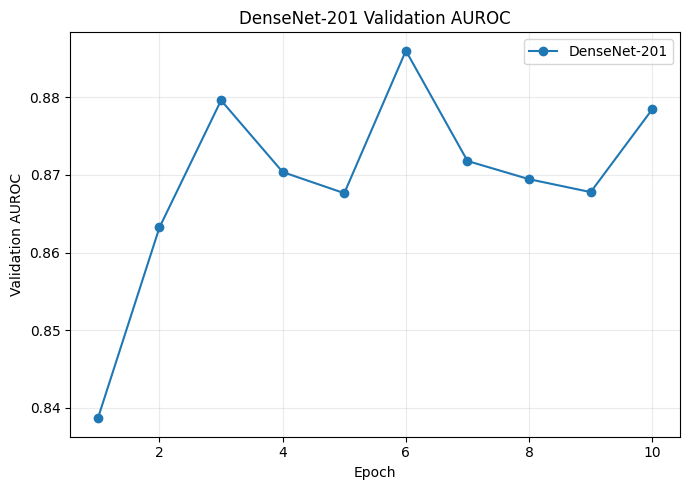

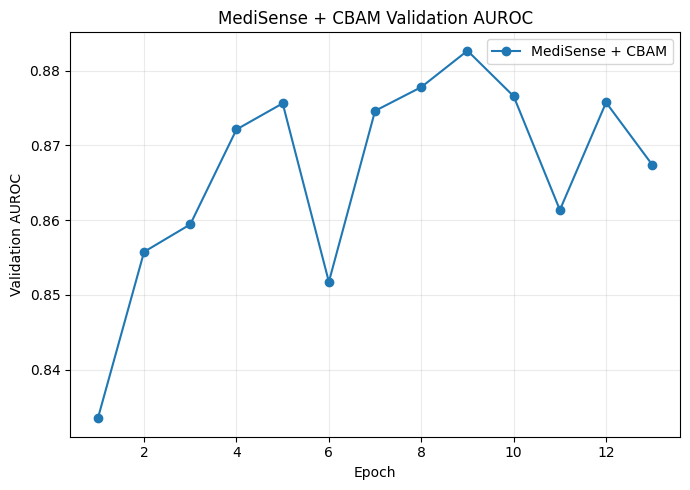

In [25]:
# 26. Validation AUROC learning curves

if baseline_history is not None:

    plt.figure(figsize=(7, 5))

    plt.plot(
        baseline_history["epoch"],
        baseline_history["val_AUROC"],
        marker="o",
        label="DenseNet-201"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Validation AUROC")
    plt.title("DenseNet-201 Validation AUROC")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


if medisense_history is not None:

    plt.figure(figsize=(7, 5))

    plt.plot(
        medisense_history["epoch"],
        medisense_history["val_AUROC"],
        marker="o",
        label="MediSense + CBAM"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Validation AUROC")
    plt.title("MediSense + CBAM Validation AUROC")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


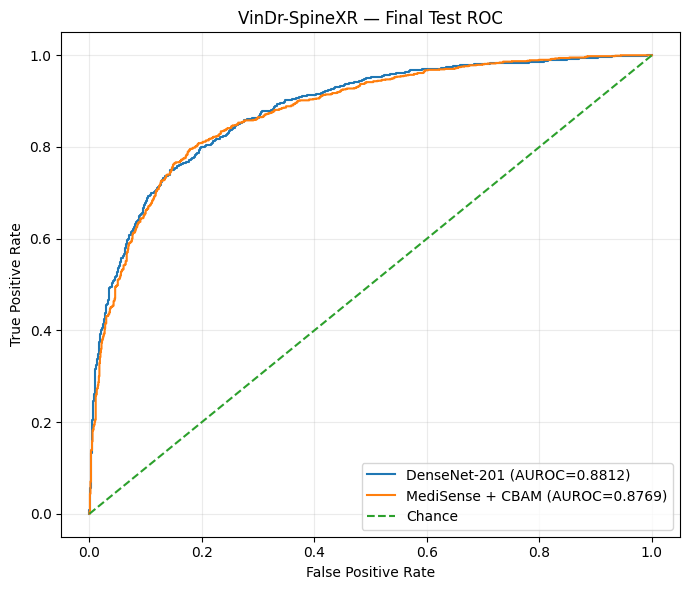

In [26]:
# 27. Final ROC curves

plt.figure(figsize=(7, 6))

if baseline_metrics is not None:

    fpr_b, tpr_b, _ = roc_curve(
        y_test_b,
        p_test_b
    )

    plt.plot(
        fpr_b,
        tpr_b,
        label=(
            f"DenseNet-201 "
            f"(AUROC={baseline_metrics['AUROC']:.4f})"
        )
    )


if medisense_metrics is not None:

    fpr_m, tpr_m, _ = roc_curve(
        y_test_m,
        p_test_m
    )

    plt.plot(
        fpr_m,
        tpr_m,
        label=(
            f"MediSense + CBAM "
            f"(AUROC={medisense_metrics['AUROC']:.4f})"
        )
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("VinDr-SpineXR — Final Test ROC")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


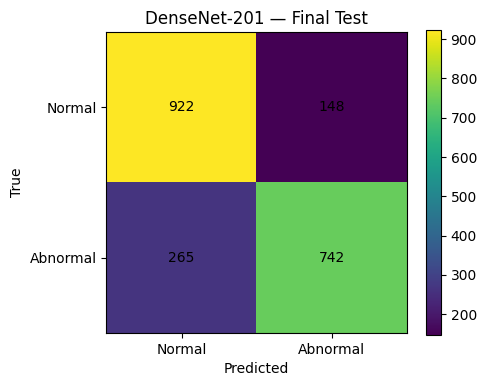

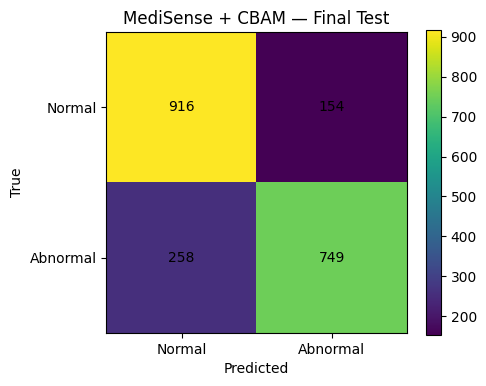

In [27]:
# 28. Final confusion matrices

def plot_confusion_matrix(
    y_true,
    y_pred,
    title
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    plt.imshow(cm)

    plt.xticks(
        [0, 1],
        ["Normal", "Abnormal"]
    )

    plt.yticks(
        [0, 1],
        ["Normal", "Abnormal"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)

    for i in range(2):
        for j in range(2):
            plt.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center"
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()


if baseline_metrics is not None:

    plot_confusion_matrix(
        y_test_b,
        baseline_pred,
        "DenseNet-201 — Final Test"
    )


if medisense_metrics is not None:

    plot_confusion_matrix(
        y_test_m,
        medisense_pred,
        "MediSense + CBAM — Final Test"
    )


In [28]:
# 29. Save MediSense test predictions

if medisense_metrics is not None:

    prediction_df = pd.DataFrame({
        "image_id": test_ids_m,
        "true_label": y_test_m,
        "abnormal_probability": p_test_m,
        "predicted_label": medisense_pred
    })

    prediction_path = (
        "/kaggle/working/"
        "medisense_spine_test_predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )

    print("Saved:", prediction_path)

    display(
        prediction_df.head(10)
    )


Saved: /kaggle/working/medisense_spine_test_predictions.csv


,image_id,true_label,abnormal_probability,predicted_label
0,000b3dad09378f680c845f8d7827d6ad,0,0.179240,0
1,000bcd6560f4551b9b74abffa5a688a0,0,0.483254,0
2,00175a890bdc7f1cc48ea616a64e6d6b,0,0.211809,0
3,001965d7ee25b931993d6b6b1adb8cc4,0,0.028597,0
4,003d256dd767bf8500bd7319d6792e21,0,0.000439,0
5,004004095d8a302b1c0815ccb044c018,1,0.983509,1
6,005c62dd9be402dcd71211d8eb039295,1,0.363147,0
7,00e30b6d3e73df2b8f2c5f279ddde16c,0,0.000020,0
8,00e35c0ab10073c0d616a17abe832448,0,0.030940,0
9,00f40c67984a9481dcaa74ecc9b4da4d,0,0.000325,0


In [29]:
# 30. Final research summary

print("=" * 75)
print("MEDISENSE SPINE — VinDr-SpineXR FINAL SUMMARY")
print("=" * 75)

print("Available train images :", len(train_split))
print("Validation images      :", len(val_split))
print("Official test images   :", len(test_df))
print("Train/test study overlap:", len(study_overlap))

print("\nReference benchmark:")
print("  VinDr-SpineXR ensemble AUROC = 0.8861")

if baseline_metrics is not None:

    print("\nDenseNet-201 baseline:")
    for name, value in baseline_metrics.items():
        print(f"  {name:20s}: {value:.4f}")

if medisense_metrics is not None:

    print("\nMediSense + CBAM:")
    for name, value in medisense_metrics.items():
        print(f"  {name:20s}: {value:.4f}")

print("\nSaved files:")
print("  /kaggle/working/medisense_spine_densenet201_baseline.pth")
print("  /kaggle/working/medisense_spine_densenet201_cbam.pth")
print("  /kaggle/working/medisense_spine_test_predictions.csv")

print("=" * 75)


MEDISENSE SPINE — VinDr-SpineXR FINAL SUMMARY
Available train images : 7513
Validation images      : 829
Official test images   : 2077
Train/test study overlap: 0

Reference benchmark:
  VinDr-SpineXR ensemble AUROC = 0.8861

DenseNet-201 baseline:
  AUROC               : 0.8812
  Accuracy            : 0.8012
  Precision           : 0.8337
  Sensitivity         : 0.7368
  Specificity         : 0.8617
  F1                  : 0.7823

MediSense + CBAM:
  AUROC               : 0.8769
  Accuracy            : 0.8016
  Precision           : 0.8295
  Sensitivity         : 0.7438
  Specificity         : 0.8561
  F1                  : 0.7843

Saved files:
  /kaggle/working/medisense_spine_densenet201_baseline.pth
  /kaggle/working/medisense_spine_densenet201_cbam.pth
  /kaggle/working/medisense_spine_test_predictions.csv


# Research interpretation — read before reporting results

### Do not change these rules after seeing the test result

1. Do not move test images into training.
2. Do not tune hyperparameters using test AUROC.
3. Do not select the classification threshold using the test set.
4. Do not duplicate the 47 missing training images.
5. Do not claim that the Kaggle mirror contains all 10,466 official images.
6. Report the actual number of images used.
7. Compare AUROC with the paper's 88.61% ensemble benchmark.
8. Keep the DenseNet-201 baseline and MediSense+CBAM experiments comparable.

### If MediSense does not beat 88.61%

That is **not a failed project**.

The result tells us that CBAM alone is insufficient under this training configuration. We can then perform a controlled ablation and improve the architecture/training protocol rather than manipulating the test set.

### If MediSense beats 88.61%

We will perform additional statistical analysis and ablation before claiming a research improvement.

The next possible extension is lesion localization using VinDr-SpineXR bounding boxes.
